In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import os

In [2]:
weather_df = pd.read_csv("../raw/weather.csv")
weather_df

,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,2024-01-01 00:00:00,22.8,19,28.0,0.2,NaN,NaN,10.7,NaN,1016.8,NaN
1,2024-01-02 00:00:00,23.4,21,27.0,0.1,NaN,NaN,11.7,NaN,1016.0,NaN
2,2024-01-03 00:00:00,19.5,17,22.0,9.7,NaN,NaN,13.0,NaN,1019.9,NaN
3,2024-01-04 00:00:00,19.1,17,21.0,0.0,NaN,NaN,8.8,NaN,1019.0,NaN
4,2024-01-05 00:00:00,20.2,18,23.0,0.0,NaN,NaN,6.5,NaN,1017.6,NaN
...,...,...,...,...,...,...,...,...,...,...,...
361,2024-12-27 00:00:00,18.4,17,20.0,0.0,NaN,NaN,14.4,NaN,1024.2,NaN
362,2024-12-28 00:00:00,18.8,15,23.0,0.0,NaN,NaN,12.3,NaN,1025.9,NaN
363,2024-12-29 00:00:00,18.0,14,22.0,0.0,NaN,NaN,10.7,NaN,1021.5,NaN
364,2024-12-30 00:00:00,17.6,13,21.0,0.0,NaN,NaN,7.3,NaN,1020.6,NaN


In [3]:
aq_df = pd.read_csv("../raw/air_quality.csv")
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_dioxide (ppm),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),methane (μg/m³)
0,2024-01-01T00:00,59.8,40.0,26.0,36.0,36.8,NaN,702.0,0.0,0.46,0.0,0.0,NaN
1,2024-01-01T01:00,60.1,40.7,23.0,33.4,36.3,NaN,716.0,0.0,0.48,0.0,0.0,NaN
2,2024-01-01T02:00,61.7,42.0,20.0,31.6,35.7,NaN,732.0,0.0,0.52,0.0,0.0,NaN
3,2024-01-01T03:00,65.2,44.5,17.0,30.4,35.2,NaN,754.0,0.0,0.52,0.0,0.0,NaN
4,2024-01-01T04:00,68.9,47.1,15.0,30.5,35.1,NaN,778.0,0.0,0.51,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31T19:00,101.7,101.5,51.0,47.8,41.9,476.0,1998.0,0.0,0.71,0.0,0.0,1747.0
8780,2024-12-31T20:00,105.2,104.8,49.0,49.3,41.0,477.0,1915.0,0.0,0.69,0.0,0.0,1766.0
8781,2024-12-31T21:00,108.5,108.3,46.0,51.2,39.6,477.0,1618.0,0.0,0.66,0.0,0.0,1765.0
8782,2024-12-31T22:00,112.9,112.7,43.0,51.4,38.1,477.0,1365.0,0.0,0.64,0.0,0.0,1765.0


In [4]:
weather_df["date"] = pd.to_datetime(weather_df["date"], errors="coerce")
weather_df["date"].isna().sum()

np.int64(0)

In [5]:
aq_df["time"] = pd.to_datetime(aq_df["time"], errors="coerce")
aq_df["time"].isna().sum()

np.int64(0)

In [6]:
qa_logs = []
def qa_log(dataset, rule, count, total):
    qa_logs.append({
        "dataset": dataset,
        "rule": rule,
        "count": int(count),
        "total": int(total),
        "percent": round(100 * count / total, 4) if total else np.nan
    })

In [7]:
weather_missing_cols = weather_df.columns.tolist()
aq_missing_cols = aq_df.columns.tolist()

for c in weather_missing_cols:
    mask = weather_df[c].isna()
    weather_df[f"flag_missing_{c}"] = mask
    qa_log("weather", f"Weather Missing {c}", mask.sum(), len(weather_df))

for c in aq_missing_cols:
    mask = aq_df[c].isna()
    aq_df[f"flag_missing_{c}"] = mask
    qa_log("air_quality", f"AQ Missing {c}", mask.sum(), len(aq_df))    

In [8]:
weather_df_neg_cols = ['prcp', 'snow', 'wspd', 'wpgt', 'pres', 'tsun']
aq_df_neg_cols = ['pm10 (μg/m³)', 'pm2_5 (μg/m³)', 'ozone (μg/m³)',
       'sulphur_dioxide (μg/m³)', 'nitrogen_dioxide (μg/m³)',
       'carbon_dioxide (ppm)', 'carbon_monoxide (μg/m³)', 'uv_index ()',
       'aerosol_optical_depth ()', 'dust (μg/m³)', 'uv_index_clear_sky ()',
       'methane (μg/m³)']

for col in weather_df_neg_cols:
    mask = weather_df[col].apply(lambda x: False if pd.isna(x) else x < 0)
    weather_df[f"flag_neg_{col}"] = mask
    qa_log("weather", f"Weather negative {col}", mask.sum(), len(weather_df))

for col in aq_df_neg_cols:
    mask = aq_df[col].apply(lambda x: False if pd.isna(x) else x < 0)
    aq_df[f"flag_neg_{col}"] = mask
    qa_log("air_quality", f"AQ negative {col}", mask.sum(), len(aq_df))

aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_dioxide (ppm),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),...,flag_neg_ozone (μg/m³),flag_neg_sulphur_dioxide (μg/m³),flag_neg_nitrogen_dioxide (μg/m³),flag_neg_carbon_dioxide (ppm),flag_neg_carbon_monoxide (μg/m³),flag_neg_uv_index (),flag_neg_aerosol_optical_depth (),flag_neg_dust (μg/m³),flag_neg_uv_index_clear_sky (),flag_neg_methane (μg/m³)
0,2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,NaN,702.0,0.0,0.46,...,False,False,False,False,False,False,False,False,False,False
1,2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,NaN,716.0,0.0,0.48,...,False,False,False,False,False,False,False,False,False,False
2,2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,NaN,732.0,0.0,0.52,...,False,False,False,False,False,False,False,False,False,False
3,2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,NaN,754.0,0.0,0.52,...,False,False,False,False,False,False,False,False,False,False
4,2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,NaN,778.0,0.0,0.51,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,476.0,1998.0,0.0,0.71,...,False,False,False,False,False,False,False,False,False,False
8780,2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,477.0,1915.0,0.0,0.69,...,False,False,False,False,False,False,False,False,False,False
8781,2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,477.0,1618.0,0.0,0.66,...,False,False,False,False,False,False,False,False,False,False
8782,2024-12-31 22:00:00,112.9,112.7,43.0,51.4,38.1,477.0,1365.0,0.0,0.64,...,False,False,False,False,False,False,False,False,False,False


In [9]:
qa_logs[:5]

[{'dataset': 'weather',
  'rule': 'Weather Missing date',
  'count': 0,
  'total': 366,
  'percent': np.float64(0.0)},
 {'dataset': 'weather',
  'rule': 'Weather Missing tavg',
  'count': 0,
  'total': 366,
  'percent': np.float64(0.0)},
 {'dataset': 'weather',
  'rule': 'Weather Missing tmin',
  'count': 0,
  'total': 366,
  'percent': np.float64(0.0)},
 {'dataset': 'weather',
  'rule': 'Weather Missing tmax',
  'count': 0,
  'total': 366,
  'percent': np.float64(0.0)},
 {'dataset': 'weather',
  'rule': 'Weather Missing prcp',
  'count': 12,
  'total': 366,
  'percent': np.float64(3.2787)}]

In [10]:
mask = (aq_df["pm2_5 (μg/m³)"].notna()) & (aq_df["pm10 (μg/m³)"].notna()) & (aq_df["pm2_5 (μg/m³)"] > aq_df["pm10 (μg/m³)"])
aq_df["flag_pm25_gt_pm10"] = mask
qa_log("air_quality", "PM2.5 > PM10", mask.sum(), len(aq_df))

In [11]:
weather_df["flag_dup_date"] = weather_df.duplicated("date", keep=False)
aq_df["flag_dup_time"] = aq_df.duplicated("time", keep=False)
qa_log("weather", "Weather duplicate timestamps", weather_df['flag_dup_date'].sum(), len(weather_df))
qa_log("air_quality", "AQ duplicate timestamps", aq_df['flag_dup_time'].sum(), len(aq_df))

In [12]:
aq_df["flag_dup_time"].value_counts()
weather_df["flag_dup_date"].value_counts()

flag_dup_date
False    366
Name: count, dtype: int64

In [13]:
start = weather_df["date"].min()
end = weather_df["date"].max()
ts = pd.date_range(start=start, end=end, freq="d")
weather_missing_ts = len(ts) - weather_df["date"].nunique()
qa_log("weather", "Weather missing timestamps", weather_missing_ts, len(ts))

start = aq_df["time"].min()
end = aq_df["time"].max()
ts = pd.date_range(start=start, end=end, freq="h")
aq_missing_ts = len(ts) - aq_df["time"].nunique()
qa_log("air_quality", "AQ missing timestamps", aq_missing_ts, len(ts))

weather_missing_ts, aq_missing_ts

(0, 0)

In [14]:
exclude_cols = ["carbon_dioxide (ppm)", "methane (μg/m³)"]

aq_remove_missing_df = aq_df.drop(columns=exclude_cols)
aq_num_cols = aq_remove_missing_df.select_dtypes(include=[np.number]).columns.tolist()
agg_map = {c: "mean" for c in aq_num_cols}
agg_map

flag_cols = [c for c in aq_remove_missing_df.columns if c.startswith("flag_")]
for c in flag_cols:
    agg_map[c] = "max"

agg_map

aq_df = aq_df.set_index("time").sort_index()
aq_daily = aq_df.resample("D").agg(agg_map)



In [15]:
aq_daily

,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),...,flag_neg_nitrogen_dioxide (μg/m³),flag_neg_carbon_dioxide (ppm),flag_neg_carbon_monoxide (μg/m³),flag_neg_uv_index (),flag_neg_aerosol_optical_depth (),flag_neg_dust (μg/m³),flag_neg_uv_index_clear_sky (),flag_neg_methane (μg/m³),flag_pm25_gt_pm10,flag_dup_time
time,,,,,,,,,,,,,,,,,,,,,
2024-01-01,70.258333,47.104167,55.500000,37.391667,29.633333,650.333333,0.760417,0.585833,0.125000,1.127083,...,False,False,False,False,False,False,False,False,False,False
2024-01-02,53.508333,35.829167,61.541667,30.045833,21.916667,512.041667,0.943750,0.560833,0.000000,1.231250,...,False,False,False,False,False,False,False,False,False,False
2024-01-03,42.762500,29.716667,53.208333,18.245833,19.083333,648.833333,0.312500,0.421250,0.250000,1.200000,...,False,False,False,False,False,False,False,False,False,False
2024-01-04,70.362500,48.320833,38.416667,41.704167,33.637500,899.708333,0.445833,0.536667,0.125000,1.181250,...,False,False,False,False,False,False,False,False,False,False
2024-01-05,86.800000,56.929167,50.000000,47.545833,36.787500,1023.583333,0.375000,0.730417,0.000000,1.060417,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,58.566667,58.354167,57.291667,38.216667,23.879167,809.708333,0.393750,0.544167,0.000000,1.068750,...,False,False,False,False,False,False,False,False,False,False
2024-12-28,52.316667,52.154167,68.541667,34.941667,26.612500,912.375000,0.989583,0.363750,0.000000,1.181250,...,False,False,False,False,False,False,False,False,False,False
2024-12-29,84.187500,83.816667,74.875000,55.833333,41.591667,905.375000,1.014583,0.561667,0.291667,1.014583,...,False,False,False,False,False,False,False,False,False,False


In [16]:
weather_df = weather_df.set_index("date").sort_index()
weather_df

,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun,...,flag_missing_wpgt,flag_missing_pres,flag_missing_tsun,flag_neg_prcp,flag_neg_snow,flag_neg_wspd,flag_neg_wpgt,flag_neg_pres,flag_neg_tsun,flag_dup_date
date,,,,,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,NaN,NaN,10.7,NaN,1016.8,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-01-02,23.4,21,27.0,0.1,NaN,NaN,11.7,NaN,1016.0,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-01-03,19.5,17,22.0,9.7,NaN,NaN,13.0,NaN,1019.9,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-01-04,19.1,17,21.0,0.0,NaN,NaN,8.8,NaN,1019.0,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-01-05,20.2,18,23.0,0.0,NaN,NaN,6.5,NaN,1017.6,NaN,...,True,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,NaN,NaN,14.4,NaN,1024.2,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-12-28,18.8,15,23.0,0.0,NaN,NaN,12.3,NaN,1025.9,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-12-29,18.0,14,22.0,0.0,NaN,NaN,10.7,NaN,1021.5,NaN,...,True,False,True,False,False,False,False,False,False,False


In [17]:
processed_dir = Path("../processed")
reports_dir = Path("../reports")

aq_daily.to_csv(processed_dir / "air_quality_clean.csv", index=True)
weather_df.to_csv(processed_dir / "weather_clean.csv", index=True)
qa_df = pd.DataFrame(qa_logs)
qa_df.to_csv(reports_dir / "qa_summary.csv", index=False)

In [18]:
qa_df

,dataset,rule,count,total,percent
0,weather,Weather Missing date,0,366,0.0000
1,weather,Weather Missing tavg,0,366,0.0000
2,weather,Weather Missing tmin,0,366,0.0000
3,weather,Weather Missing tmax,0,366,0.0000
4,weather,Weather Missing prcp,12,366,3.2787
5,weather,Weather Missing snow,366,366,100.0000
6,weather,Weather Missing wdir,366,366,100.0000
7,weather,Weather Missing wspd,0,366,0.0000
8,weather,Weather Missing wpgt,366,366,100.0000
9,weather,Weather Missing pres,0,366,0.0000


In [19]:
aq_df

,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_dioxide (ppm),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),...,flag_neg_nitrogen_dioxide (μg/m³),flag_neg_carbon_dioxide (ppm),flag_neg_carbon_monoxide (μg/m³),flag_neg_uv_index (),flag_neg_aerosol_optical_depth (),flag_neg_dust (μg/m³),flag_neg_uv_index_clear_sky (),flag_neg_methane (μg/m³),flag_pm25_gt_pm10,flag_dup_time
time,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,NaN,702.0,0.0,0.46,0.0,...,False,False,False,False,False,False,False,False,False,False
2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,NaN,716.0,0.0,0.48,0.0,...,False,False,False,False,False,False,False,False,False,False
2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,NaN,732.0,0.0,0.52,0.0,...,False,False,False,False,False,False,False,False,False,False
2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,NaN,754.0,0.0,0.52,0.0,...,False,False,False,False,False,False,False,False,False,False
2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,NaN,778.0,0.0,0.51,0.0,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,476.0,1998.0,0.0,0.71,0.0,...,False,False,False,False,False,False,False,False,False,False
2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,477.0,1915.0,0.0,0.69,0.0,...,False,False,False,False,False,False,False,False,False,False
2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,477.0,1618.0,0.0,0.66,0.0,...,False,False,False,False,False,False,False,False,False,False


In [20]:
weather_df

,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun,...,flag_missing_wpgt,flag_missing_pres,flag_missing_tsun,flag_neg_prcp,flag_neg_snow,flag_neg_wspd,flag_neg_wpgt,flag_neg_pres,flag_neg_tsun,flag_dup_date
date,,,,,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,NaN,NaN,10.7,NaN,1016.8,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-01-02,23.4,21,27.0,0.1,NaN,NaN,11.7,NaN,1016.0,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-01-03,19.5,17,22.0,9.7,NaN,NaN,13.0,NaN,1019.9,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-01-04,19.1,17,21.0,0.0,NaN,NaN,8.8,NaN,1019.0,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-01-05,20.2,18,23.0,0.0,NaN,NaN,6.5,NaN,1017.6,NaN,...,True,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,NaN,NaN,14.4,NaN,1024.2,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-12-28,18.8,15,23.0,0.0,NaN,NaN,12.3,NaN,1025.9,NaN,...,True,False,True,False,False,False,False,False,False,False
2024-12-29,18.0,14,22.0,0.0,NaN,NaN,10.7,NaN,1021.5,NaN,...,True,False,True,False,False,False,False,False,False,False


<Axes: xlabel='date', ylabel='prcp'>

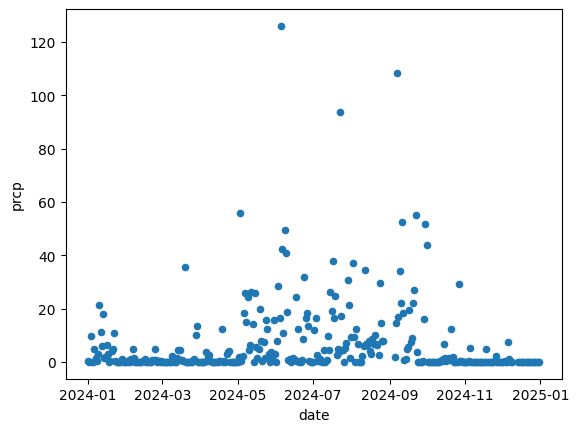

In [26]:
weather_df.reset_index().plot(kind="scatter", x="date", y="prcp")